## Q1. Principal Component Analysis (PCA) on PIE Face Dataset

In [2]:
# Numerical computing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Image processing
from PIL import Image

# File handling
from pathlib import Path

# Reproducibility
np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw" / "PCA_PIE_Data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
# Create output directories if they don't exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw dataset:", RAW_DATA_DIR)
print("Processed dataset:", PROCESSED_DATA_DIR)

assert RAW_DATA_DIR.exists(), "PIE dataset not found!"
assert PROCESSED_DATA_DIR.exists(), "Processed dataset not found!"

Project root: /home/aryan/projects/dsl502-assignment
Raw dataset: /home/aryan/projects/dsl502-assignment/data/raw/PCA_PIE_Data
Processed dataset: /home/aryan/projects/dsl502-assignment/data/processed


In [5]:
dataset_file = PROCESSED_DATA_DIR / "pie_dataset.npz"

with np.load(dataset_file) as data:
    X_lights = data["X_lights"]
    X_nolights = data["X_nolights"]

print("Lights matrix:", X_lights.shape)
print("Nolights matrix:", X_nolights.shape)

assert X_lights.shape == (105, 10000)
assert X_nolights.shape == (105, 10000)

Lights matrix: (105, 10000)
Nolights matrix: (105, 10000)


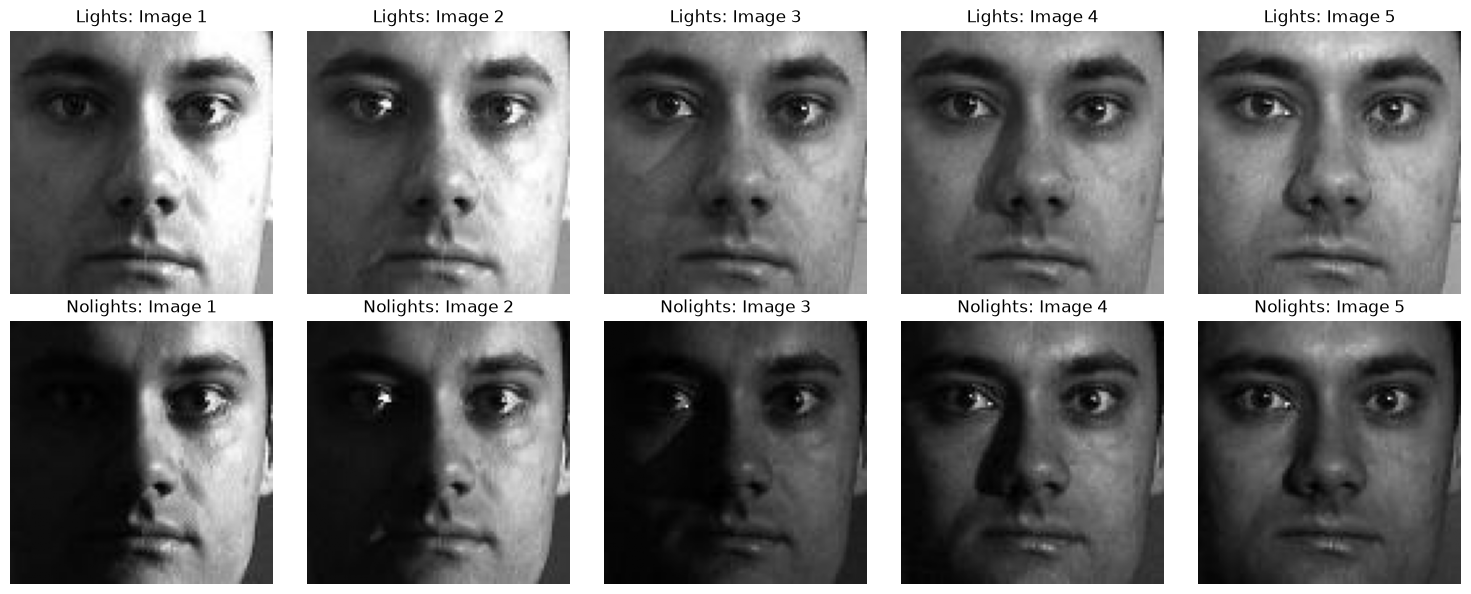

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):

    axes[0, i].imshow(
        X_lights[i].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, i].set_title(f"Lights: Image {i+1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        X_nolights[i].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title(f"Nolights: Image {i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

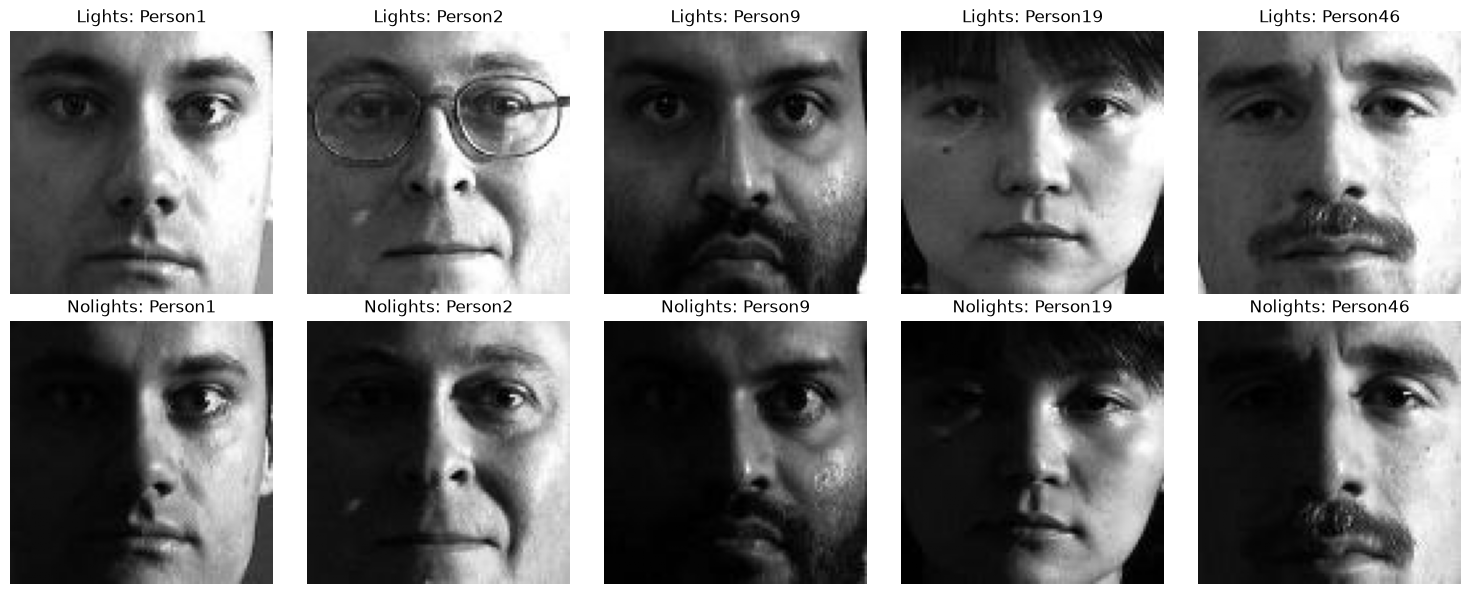

In [7]:
# Compare five different persons under the same flash direction

person_names = [
    "Person1",
    "Person2",
    "Person9",
    "Person19",
    "Person46"
]

# Each person has 21 consecutive images
indices = [0, 21, 42, 63, 84]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, (person, idx) in enumerate(zip(person_names, indices)):

    axes[0, i].imshow(
        X_lights[idx].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, i].set_title(f"Lights: {person}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        X_nolights[idx].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title(f"Nolights: {person}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


Lights:
Mean face shape: (10000,)
Centered matrix shape: (105, 10000)

Nolights:
Mean face shape: (10000,)
Centered matrix shape: (105, 10000)


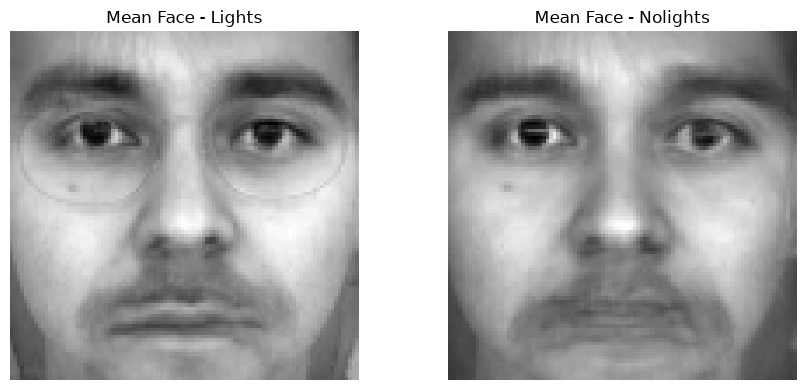

In [8]:

# Q1: PCA - Mean Centering

# Calculate mean face for each lighting condition
mean_lights = np.mean(X_lights, axis=0)
mean_nolights = np.mean(X_nolights, axis=0)

# Subtract mean face from every image
Xc_lights = X_lights - mean_lights
Xc_nolights = X_nolights - mean_nolights

# Verify dimensions
print("Lights:")
print("Mean face shape:", mean_lights.shape)
print("Centered matrix shape:", Xc_lights.shape)

print("\nNolights:")
print("Mean face shape:", mean_nolights.shape)
print("Centered matrix shape:", Xc_nolights.shape)

# Visualize mean faces
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(mean_lights.reshape(100, 100), cmap="gray")
axes[0].set_title("Mean Face - Lights")
axes[0].axis("off")

axes[1].imshow(mean_nolights.reshape(100, 100), cmap="gray")
axes[1].set_title("Mean Face - Nolights")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
# --------------------------------------------------
# PCA: Gram Matrix and Eigen Decomposition
# --------------------------------------------------

def compute_pca(X_centered):

    n_samples = X_centered.shape[0]

    # Step 1: Compute smaller covariance (Gram) matrix
    G = (X_centered @ X_centered.T) / (n_samples - 1)

    # Step 2: Eigenvalue and eigenvector decomposition
    eigenvalues, eigenvectors = np.linalg.eigh(G)

    # Step 3: Sort eigenvalues in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]

    # Step 4: Remove tiny negative numerical errors
    eigenvalues = np.maximum(eigenvalues, 0)

    # Step 5: Convert eigenvectors into original pixel space
    positive = eigenvalues > 1e-10

    eigenvalues = eigenvalues[positive]
    eigenvectors = eigenvectors[:, positive]

    principal_components = (
        X_centered.T @ eigenvectors
    ) / np.sqrt((n_samples - 1) * eigenvalues)

    return eigenvalues, principal_components.T, G


# PCA separately for both lighting conditions
eigenvalues_lights, PC_lights, G_lights = compute_pca(Xc_lights)

eigenvalues_nolights, PC_nolights, G_nolights = compute_pca(Xc_nolights)


# Verify results
print("LIGHTS")
print("Gram matrix:", G_lights.shape)
print("Eigenvalues:", eigenvalues_lights.shape)
print("Principal components:", PC_lights.shape)

print("\nNOLIGHTS")
print("Gram matrix:", G_nolights.shape)
print("Eigenvalues:", eigenvalues_nolights.shape)
print("Principal components:", PC_nolights.shape)

LIGHTS
Gram matrix: (105, 105)
Eigenvalues: (104,)
Principal components: (104, 10000)

NOLIGHTS
Gram matrix: (105, 105)
Eigenvalues: (104,)
Principal components: (104, 10000)


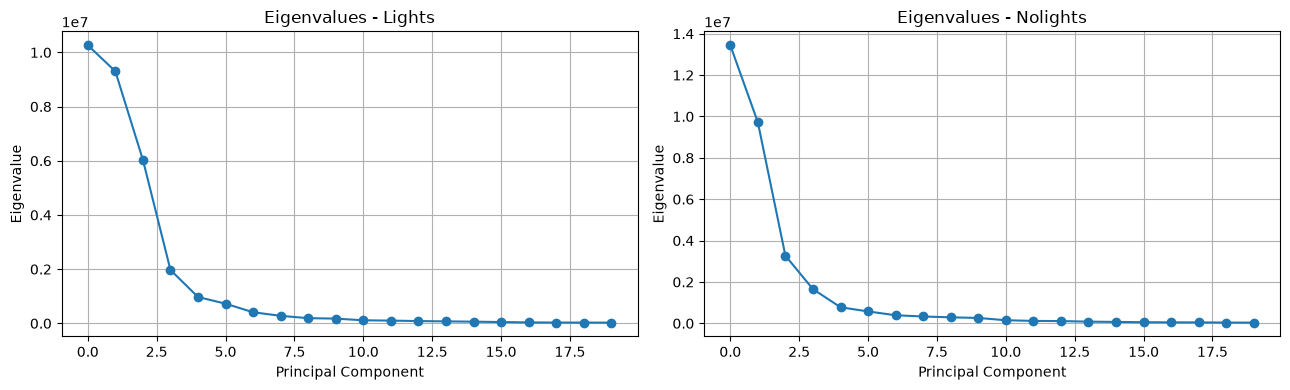

In [10]:
# Plot the first 20 eigenvalues

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(eigenvalues_lights[:20], marker="o")
axes[0].set_title("Eigenvalues - Lights")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Eigenvalue")
axes[0].grid(True)

axes[1].plot(eigenvalues_nolights[:20], marker="o")
axes[1].set_title("Eigenvalues - Nolights")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("Eigenvalue")
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [11]:
print("Lights - PC1 eigenvalue:", eigenvalues_lights[0])
print("Lights - PC2 eigenvalue:", eigenvalues_lights[1])

print("\nPC1 vector norm:", np.linalg.norm(PC_lights[0]))
print("PC2 vector norm:", np.linalg.norm(PC_lights[1]))

print("\nPC1-PC2 dot product:",
      np.dot(PC_lights[0], PC_lights[1]))

Lights - PC1 eigenvalue: 10265390.065828394
Lights - PC2 eigenvalue: 9301766.811844628

PC1 vector norm: 0.9999999999999999
PC2 vector norm: 1.0000000000000002

PC1-PC2 dot product: 1.448494102440634e-16


LIGHTS
PC1: EVR = 32.685% | Cumulative = 32.685%
PC2: EVR = 29.617% | Cumulative = 62.301%
PC3: EVR = 19.215% | Cumulative = 81.516%
PC4: EVR = 6.275% | Cumulative = 87.791%
PC5: EVR = 3.095% | Cumulative = 90.886%
PC6: EVR = 2.312% | Cumulative = 93.198%
PC7: EVR = 1.304% | Cumulative = 94.502%
PC8: EVR = 0.883% | Cumulative = 95.384%
PC9: EVR = 0.609% | Cumulative = 95.993%

NOLIGHTS
PC1: EVR = 42.043% | Cumulative = 42.043%
PC2: EVR = 30.393% | Cumulative = 72.437%
PC3: EVR = 10.227% | Cumulative = 82.663%
PC4: EVR = 5.173% | Cumulative = 87.836%
PC5: EVR = 2.434% | Cumulative = 90.270%
PC6: EVR = 1.802% | Cumulative = 92.072%
PC7: EVR = 1.223% | Cumulative = 93.294%
PC8: EVR = 1.036% | Cumulative = 94.330%
PC9: EVR = 0.910% | Cumulative = 95.240%


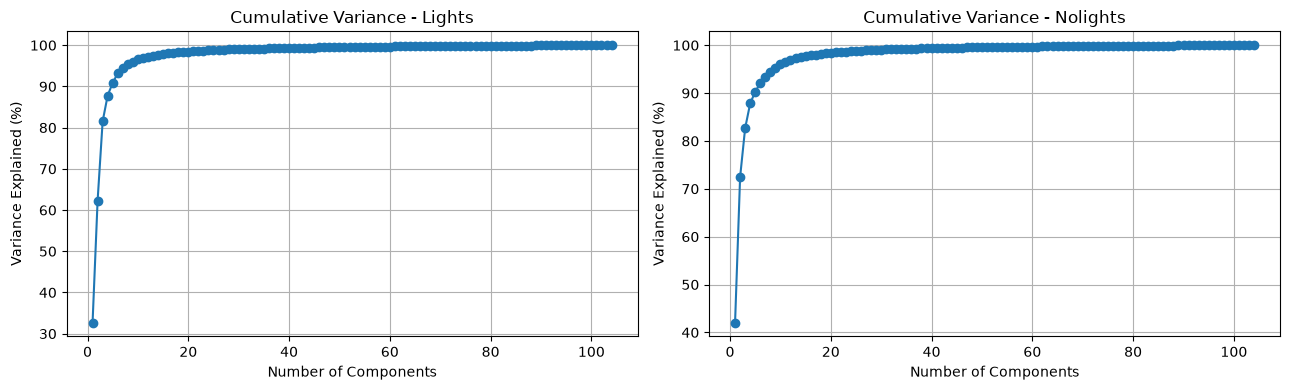

In [12]:
# --------------------------------------------------
# PCA: Explained Variance Analysis
# --------------------------------------------------

def explained_variance_analysis(eigenvalues):

    explained_variance_ratio = (
        eigenvalues / np.sum(eigenvalues)
    )

    cumulative_variance = np.cumsum(
        explained_variance_ratio
    )

    return explained_variance_ratio, cumulative_variance


# Calculate for both lighting conditions
evr_lights, cumulative_lights = explained_variance_analysis(
    eigenvalues_lights
)

evr_nolights, cumulative_nolights = explained_variance_analysis(
    eigenvalues_nolights
)


# Display first 9 components
print("LIGHTS")
for i in range(9):
    print(
        f"PC{i+1}: "
        f"EVR = {evr_lights[i]*100:.3f}% | "
        f"Cumulative = {cumulative_lights[i]*100:.3f}%"
    )

print("\nNOLIGHTS")
for i in range(9):
    print(
        f"PC{i+1}: "
        f"EVR = {evr_nolights[i]*100:.3f}% | "
        f"Cumulative = {cumulative_nolights[i]*100:.3f}%"
    )


# Plot cumulative explained variance
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    np.arange(1, len(cumulative_lights)+1),
    cumulative_lights * 100,
    marker="o"
)
axes[0].set_title("Cumulative Variance - Lights")
axes[0].set_xlabel("Number of Components")
axes[0].set_ylabel("Variance Explained (%)")
axes[0].grid(True)

axes[1].plot(
    np.arange(1, len(cumulative_nolights)+1),
    cumulative_nolights * 100,
    marker="o"
)
axes[1].set_title("Cumulative Variance - Nolights")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Variance Explained (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [13]:

# --------------------------------------------------
# PCA: Image Reconstruction
# --------------------------------------------------

def reconstruct_image(image, mean_face, principal_components, selected_indices):

    # Center the original image
    centered_image = image - mean_face

    # Select required principal components
    selected_components = principal_components[selected_indices]

    # Project image into selected PCA space
    coefficients = centered_image @ selected_components.T

    # Reconstruct image
    reconstructed = (
        mean_face +
        coefficients @ selected_components
    )

    return reconstructed.reshape(100, 100)


# Selected PC ranges (Python uses zero-based indexing)
pc_1_3 = [0, 1, 2]
pc_5_9 = [4, 5, 6, 7, 8]

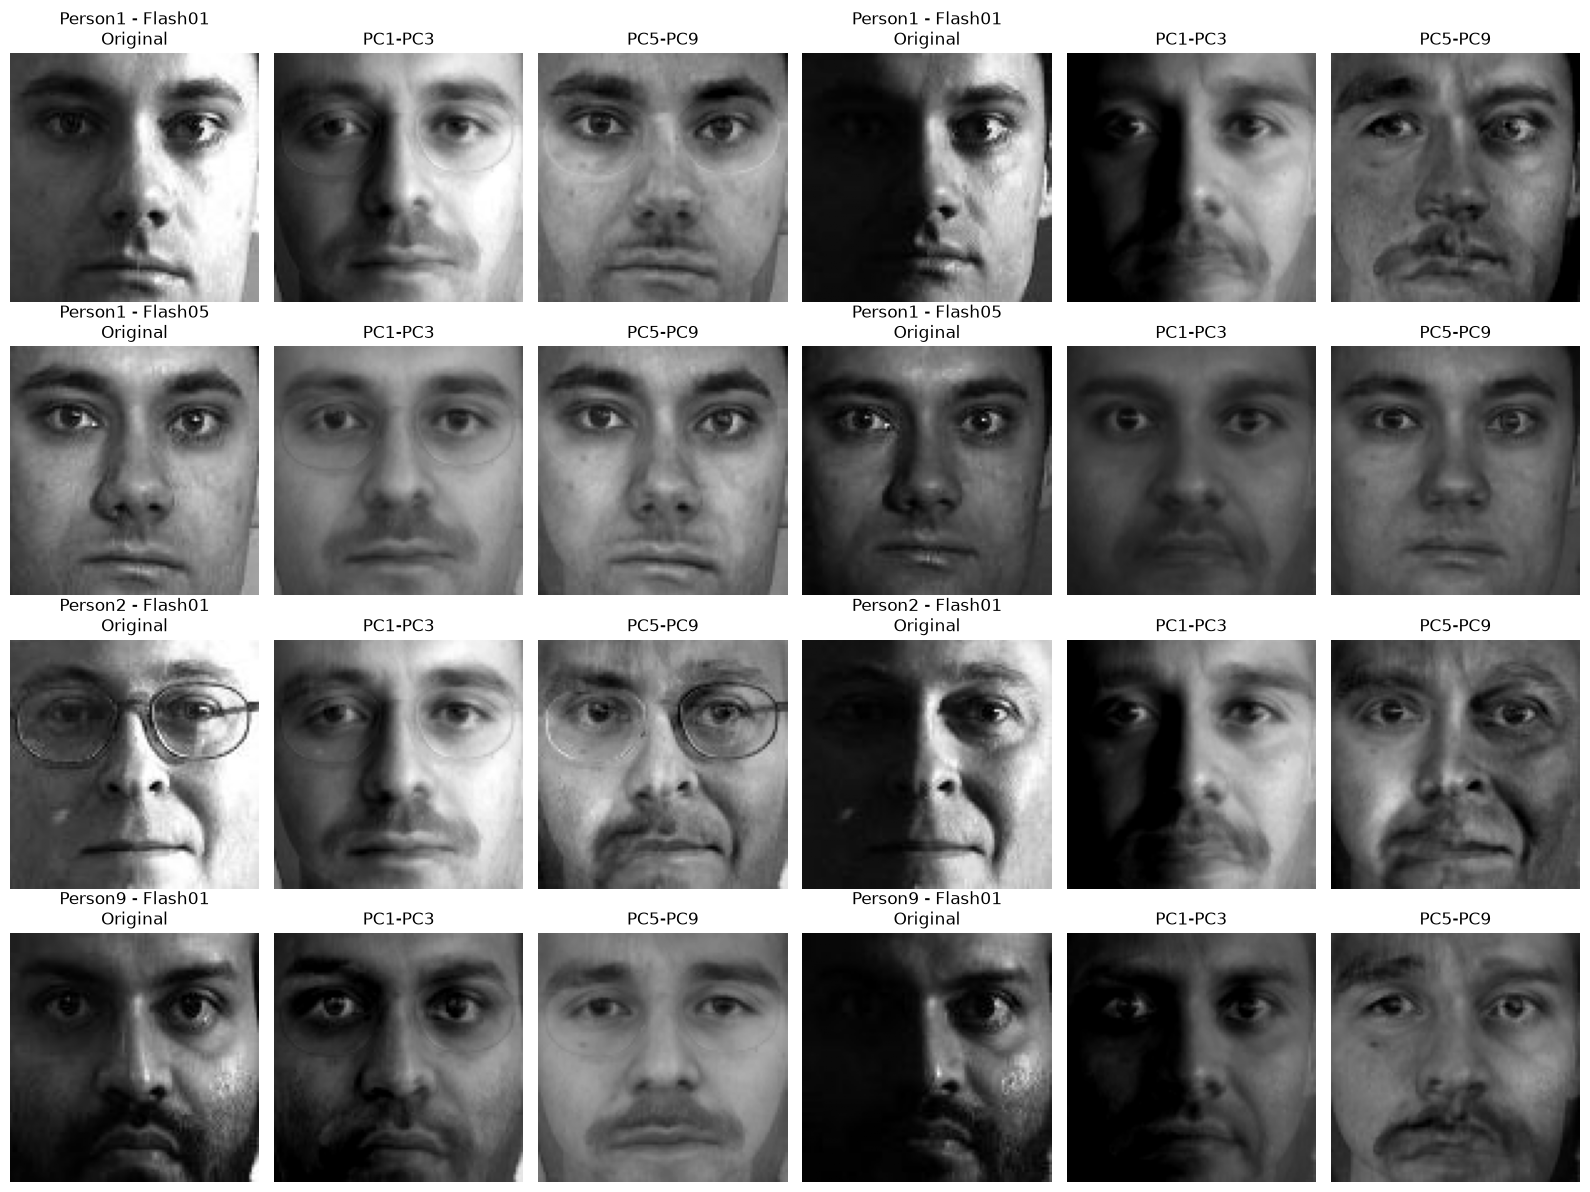

In [14]:

# --------------------------------------------------
# Reconstruct selected images using PC1-3 and PC5-9
# --------------------------------------------------

selected_images = {
    "Person1 - Flash01": 0,
    "Person1 - Flash05": 4,
    "Person2 - Flash01": 21,
    "Person9 - Flash01": 42
}

fig, axes = plt.subplots(4, 6, figsize=(16, 12))

for row, (name, idx) in enumerate(selected_images.items()):

    # Original image
    axes[row, 0].imshow(
        X_lights[idx].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 0].set_title(f"{name}\nOriginal")

    # PC1-PC3 reconstruction
    rec_1_3 = reconstruct_image(
        X_lights[idx],
        mean_lights,
        PC_lights,
        pc_1_3
    )

    axes[row, 1].imshow(
        rec_1_3,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 1].set_title("PC1-PC3")

    # PC5-PC9 reconstruction
    rec_5_9 = reconstruct_image(
        X_lights[idx],
        mean_lights,
        PC_lights,
        pc_5_9
    )

    axes[row, 2].imshow(
        rec_5_9,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 2].set_title("PC5-PC9")

    # Nolights original
    axes[row, 3].imshow(
        X_nolights[idx].reshape(100, 100),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 3].set_title(f"{name}\nOriginal")

    # Nolights PC1-PC3
    rec_nl_1_3 = reconstruct_image(
        X_nolights[idx],
        mean_nolights,
        PC_nolights,
        pc_1_3
    )

    axes[row, 4].imshow(
        rec_nl_1_3,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 4].set_title("PC1-PC3")

    # Nolights PC5-PC9
    rec_nl_5_9 = reconstruct_image(
        X_nolights[idx],
        mean_nolights,
        PC_nolights,
        pc_5_9
    )

    axes[row, 5].imshow(
        rec_nl_5_9,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 5].set_title("PC5-PC9")

    for col in range(6):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [15]:

# --------------------------------------------------
# PCA: Quantitative Reconstruction Evaluation
# --------------------------------------------------

def calculate_mse(original, reconstructed):

    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.mean((original - reconstructed) ** 2)


selected_images = {
    "Person1_Flash01": 0,
    "Person1_Flash05": 4,
    "Person2_Flash01": 21,
    "Person9_Flash01": 42
}

results = []

for image_name, idx in selected_images.items():

    for condition, X, mean_face, PCs in [
        ("Lights", X_lights, mean_lights, PC_lights),
        ("Nolights", X_nolights, mean_nolights, PC_nolights)
    ]:

        original = X[idx]

        # PC1-PC3
        rec_1_3 = reconstruct_image(
            original, mean_face, PCs, [0, 1, 2]
        ).flatten()

        # PC5-PC9
        rec_5_9 = reconstruct_image(
            original, mean_face, PCs, [4, 5, 6, 7, 8]
        ).flatten()

        # PC1-PC9 (additional comparison)
        rec_1_9 = reconstruct_image(
            original, mean_face, PCs, list(range(9))
        ).flatten()

        results.append({
            "Image": image_name,
            "Condition": condition,
            "MSE_PC1_PC3": calculate_mse(original, rec_1_3),
            "MSE_PC5_PC9": calculate_mse(original, rec_5_9),
            "MSE_PC1_PC9": calculate_mse(original, rec_1_9)
        })

mse_df = pd.DataFrame(results)

display(mse_df.round(2))

,Image,Condition,MSE_PC1_PC3,MSE_PC5_PC9,MSE_PC1_PC9
0,Person1_Flash01,Lights,1004.82,5348.88,491.92
1,Person1_Flash01,Nolights,1170.47,5077.19,507.65
2,Person1_Flash05,Lights,400.96,435.77,46.57
3,Person1_Flash05,Nolights,354.73,717.95,52.13
4,Person2_Flash01,Lights,1808.03,5150.31,221.40
5,Person2_Flash01,Nolights,2011.73,6447.30,438.57
6,Person9_Flash01,Lights,435.66,4356.26,310.11
7,Person9_Flash01,Nolights,561.81,3536.26,246.81


In [16]:

# --------------------------------------------------
# PCA: Reconstruction Error Across Entire Dataset
# --------------------------------------------------

def evaluate_all_images(X, mean_face, PCs):

    mse_results = {
        "PC1-PC3": [],
        "PC5-PC9": [],
        "PC1-PC9": []
    }

    for image in X:

        original = image

        for name, indices in [
            ("PC1-PC3", [0, 1, 2]),
            ("PC5-PC9", [4, 5, 6, 7, 8]),
            ("PC1-PC9", list(range(9)))
        ]:

            reconstructed = reconstruct_image(
                image,
                mean_face,
                PCs,
                indices
            ).flatten()

            mse = calculate_mse(
                original,
                reconstructed
            )

            mse_results[name].append(mse)

    return {
        name: np.mean(errors)
        for name, errors in mse_results.items()
    }


lights_all_mse = evaluate_all_images(
    X_lights, mean_lights, PC_lights
)

nolights_all_mse = evaluate_all_images(
    X_nolights, mean_nolights, PC_nolights
)

comparison_df = pd.DataFrame({
    "Lights": lights_all_mse,
    "Nolights": nolights_all_mse
})

display(comparison_df.round(2))

,Lights,Nolights
PC1-PC3,575.00,549.10
PC5-PC9,2855.66,2932.77
PC1-PC9,124.64,150.76


## Q2. Linear Discriminant Analysis (LDA) for Face Class Separation

In [17]:

# --------------------------------------------------
# Q2: LDA - Dataset Preparation
# --------------------------------------------------

PERSONS = [
    "Person1",
    "Person2",
    "Person9",
    "Person19",
    "Person46"
]

# Each person has 21 images
y = np.repeat(PERSONS, 21)

# PCA preprocessing dimension
N_PCA_COMPONENTS = 30

print("Dataset shape:", X_lights.shape)
print("Label shape:", y.shape)
print("\nPerson distribution:")

for person in PERSONS:
    print(person, ":", np.sum(y == person))

assert len(y) == 105
assert len(np.unique(y)) == 5

Dataset shape: (105, 10000)
Label shape: (105,)

Person distribution:
Person1 : 21
Person2 : 21
Person9 : 21
Person19 : 21
Person46 : 21


In [18]:
# --------------------------------------------------
# Q2: PCA Preprocessing for LDA
# --------------------------------------------------

# Select first 30 principal components
pca_lights = PC_lights[:N_PCA_COMPONENTS]
pca_nolights = PC_nolights[:N_PCA_COMPONENTS]

# Project centered images into 30-dimensional PCA space
Z_lights = Xc_lights @ pca_lights.T
Z_nolights = Xc_nolights @ pca_nolights.T

print("Lights reduced matrix:", Z_lights.shape)
print("Nolights reduced matrix:", Z_nolights.shape)

assert Z_lights.shape == (105, 30)
assert Z_nolights.shape == (105, 30)


Lights reduced matrix: (105, 30)
Nolights reduced matrix: (105, 30)


In [19]:

# --------------------------------------------------
# Q2: Calculate Within-Class and Between-Class Scatter
# --------------------------------------------------

def calculate_scatter_matrices(Z, labels):

    n_features = Z.shape[1]

    overall_mean = np.mean(Z, axis=0)

    S_W = np.zeros((n_features, n_features))
    S_B = np.zeros((n_features, n_features))

    classes = np.unique(labels)

    for person in classes:

        # Extract samples belonging to this person
        class_samples = Z[labels == person]

        # Number of samples in this class
        n_class = class_samples.shape[0]

        # Mean vector of this class
        class_mean = np.mean(class_samples, axis=0)

        # Within-class scatter
        centered_class = class_samples - class_mean

        S_W += centered_class.T @ centered_class

        # Between-class scatter
        mean_difference = (class_mean - overall_mean).reshape(-1, 1)

        S_B += n_class * (mean_difference @ mean_difference.T)

    return S_W, S_B


# Calculate for both conditions
SW_lights, SB_lights = calculate_scatter_matrices(
    Z_lights, y
)

SW_nolights, SB_nolights = calculate_scatter_matrices(
    Z_nolights, y
)

print("LIGHTS")
print("Within-class scatter:", SW_lights.shape)
print("Between-class scatter:", SB_lights.shape)

print("\nNOLIGHTS")
print("Within-class scatter:", SW_nolights.shape)
print("Between-class scatter:", SB_nolights.shape)


LIGHTS
Within-class scatter: (30, 30)
Between-class scatter: (30, 30)

NOLIGHTS
Within-class scatter: (30, 30)
Between-class scatter: (30, 30)


In [20]:
print("Lights SW rank:", np.linalg.matrix_rank(SW_lights))
print("Lights SB rank:", np.linalg.matrix_rank(SB_lights))

print("Nolights SW rank:", np.linalg.matrix_rank(SW_nolights))
print("Nolights SB rank:", np.linalg.matrix_rank(SB_nolights))

Lights SW rank: 30
Lights SB rank: 4
Nolights SW rank: 30
Nolights SB rank: 4


In [28]:

# --------------------------------------------------
# Q2: Manual LDA Eigen Decomposition
# --------------------------------------------------


def compute_lda(S_W, S_B, labels):

    # Step 1: Eigen decomposition of within-class scatter
    sw_values, sw_vectors = np.linalg.eigh(S_W)

    # Step 2: Inverse square root
    SW_inv_sqrt = (
        sw_vectors * (1.0 / np.sqrt(sw_values))
    ) @ sw_vectors.T

    # Step 3: Symmetric transformation
    A = SW_inv_sqrt @ S_B @ SW_inv_sqrt
    A = (A + A.T) / 2

    # Step 4: Eigen decomposition
    eigenvalues, eigenvectors = np.linalg.eigh(A)

    # Step 5: Descending order
    indices = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[indices]
    eigenvectors = eigenvectors[:, indices]

    # Step 6: Recover LDA directions
    W_lda = SW_inv_sqrt @ eigenvectors

    # Step 7: Retain C-1 meaningful components
    n_components = len(np.unique(labels)) - 1

    W_lda = W_lda[:, :n_components]
    eigenvalues = eigenvalues[:n_components]

    return eigenvalues, W_lda


# Recalculate both LDA models
lda_values_lights, W_lda_lights = compute_lda(
    SW_lights, SB_lights, y
)

lda_values_nolights, W_lda_nolights = compute_lda(
    SW_nolights, SB_nolights, y
)


print("LIGHTS")
print("LDA eigenvalues:", lda_values_lights)
print("LDA directions:", W_lda_lights.shape)

print("\nNOLIGHTS")
print("LDA eigenvalues:", lda_values_nolights)
print("LDA directions:", W_lda_nolights.shape)


LIGHTS
LDA eigenvalues: [799.76827989 444.57522549 199.7775327  155.81418606]
LDA directions: (30, 4)

NOLIGHTS
LDA eigenvalues: [333.58996316 207.73123527  43.92481555  31.96224644]
LDA directions: (30, 4)


In [29]:

# --------------------------------------------------
# Q2: LDA Projection
# --------------------------------------------------

Y_lights = Z_lights @ W_lda_lights
Y_nolights = Z_nolights @ W_lda_nolights

print("Lights LDA projection:", Y_lights.shape)
print("Nolights LDA projection:", Y_nolights.shape)

assert Y_lights.shape == (105, 4)
assert Y_nolights.shape == (105, 4)


Lights LDA projection: (105, 4)
Nolights LDA projection: (105, 4)


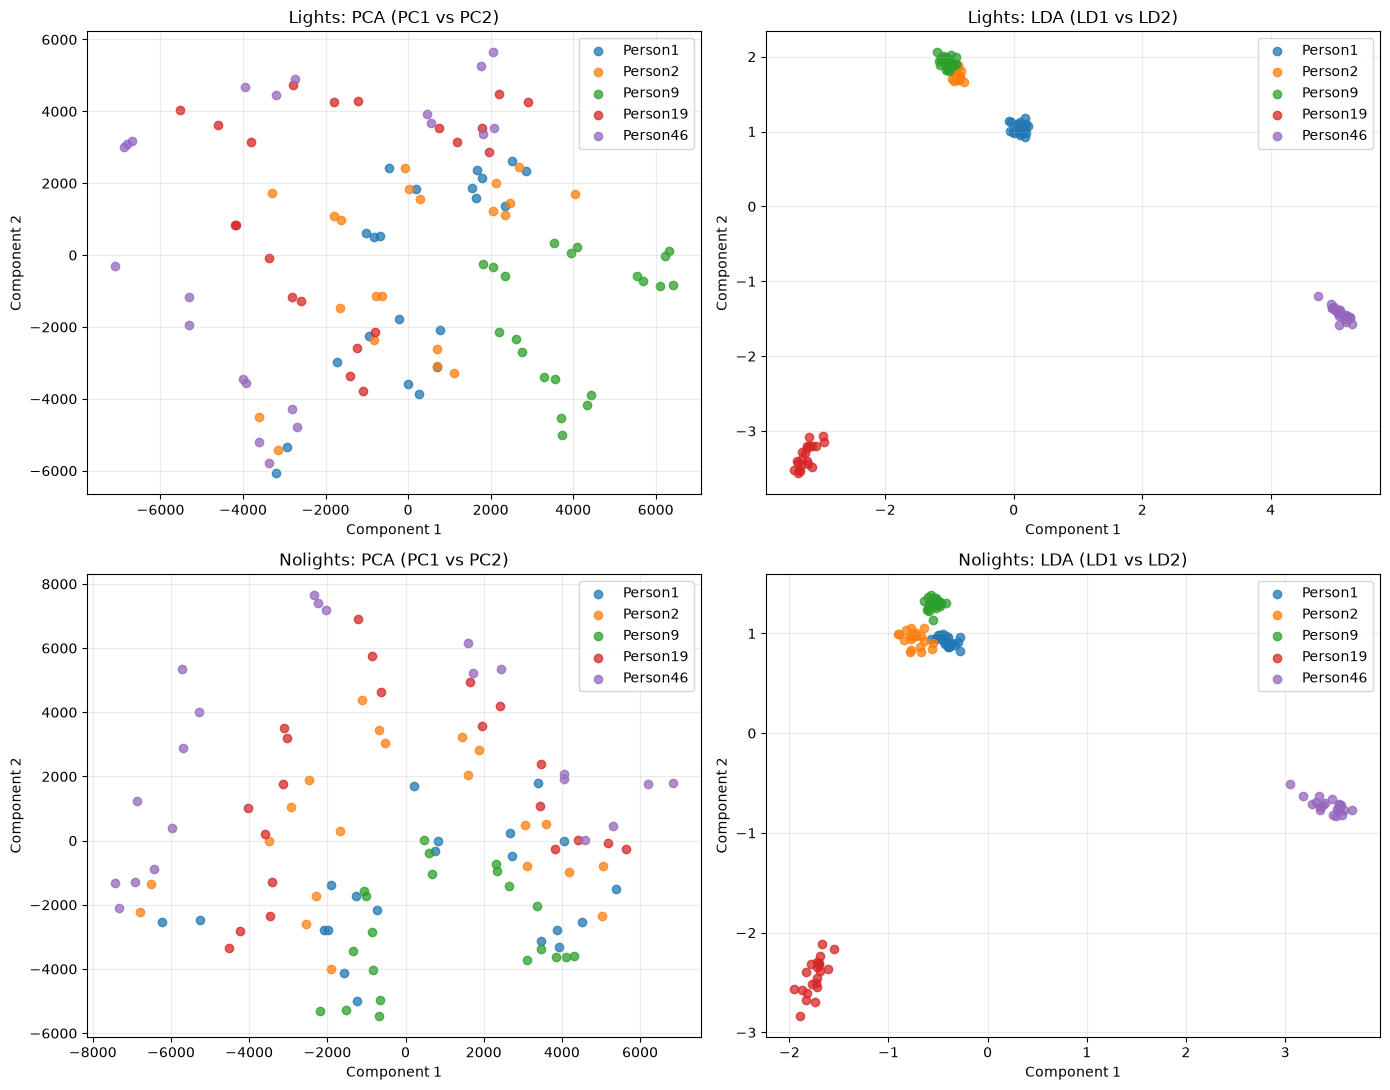

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for person in PERSONS:
    mask = y == person

    axes[0, 0].scatter(
        Z_lights[mask, 0], Z_lights[mask, 1],
        label=person, alpha=0.75
    )

    axes[0, 1].scatter(
        Y_lights[mask, 0], Y_lights[mask, 1],
        label=person, alpha=0.75
    )

    axes[1, 0].scatter(
        Z_nolights[mask, 0], Z_nolights[mask, 1],
        label=person, alpha=0.75
    )

    axes[1, 1].scatter(
        Y_nolights[mask, 0], Y_nolights[mask, 1],
        label=person, alpha=0.75
    )

axes[0, 0].set_title("Lights: PCA (PC1 vs PC2)")
axes[0, 1].set_title("Lights: LDA (LD1 vs LD2)")
axes[1, 0].set_title("Nolights: PCA (PC1 vs PC2)")
axes[1, 1].set_title("Nolights: LDA (LD1 vs LD2)")

for ax in axes.flat:
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q2_pca_vs_lda.png", dpi=200)
plt.show()

In [31]:
def calculate_separation_ratio(features, labels):
    overall_mean = np.mean(features, axis=0)

    within_scatter = 0
    between_scatter = 0

    for person in np.unique(labels):
        samples = features[labels == person]
        class_mean = np.mean(samples, axis=0)

        within_scatter += np.sum((samples - class_mean) ** 2)

        n = len(samples)
        between_scatter += n * np.sum((class_mean - overall_mean) ** 2)

    return between_scatter / within_scatter


results = {
    "Lights PCA (PC1-PC2)": calculate_separation_ratio(
        Z_lights[:, :2], y
    ),
    "Lights LDA (LD1-LD2)": calculate_separation_ratio(
        Y_lights[:, :2], y
    ),
    "Nolights PCA (PC1-PC2)": calculate_separation_ratio(
        Z_nolights[:, :2], y
    ),
    "Nolights LDA (LD1-LD2)": calculate_separation_ratio(
        Y_nolights[:, :2], y
    )
}

for name, score in results.items():
    print(f"{name}: {score:.4f}")

Lights PCA (PC1-PC2): 0.5142
Lights LDA (LD1-LD2): 622.1718
Nolights PCA (PC1-PC2): 0.2563
Nolights LDA (LD1-LD2): 270.6606


In [32]:
from itertools import combinations

def evaluate_person_combinations(X_centered, labels, persons):
    results = []

    for selected_persons in combinations(persons, 3):
        mask = np.isin(labels, selected_persons)

        X_subset = X_centered[mask]
        y_subset = labels[mask]

        # PCA features: first 30 components
        mean_subset = np.mean(X_subset, axis=0)
        Xc_subset = X_subset - mean_subset

        G = (Xc_subset @ Xc_subset.T) / (len(Xc_subset) - 1)

        eigvals, eigvecs = np.linalg.eigh(G)
        idx = np.argsort(eigvals)[::-1]

        eigvals = np.maximum(eigvals[idx], 0)
        eigvecs = eigvecs[:, idx]

        positive = eigvals > 1e-10
        eigvals = eigvals[positive][:30]
        eigvecs = eigvecs[:, positive][:, :30]

        PCs = (
            Xc_subset.T @ eigvecs
        ) / np.sqrt((len(Xc_subset) - 1) * eigvals)

        Z = Xc_subset @ PCs

        SW, SB = calculate_scatter_matrices(Z, y_subset)
        lda_values, W = compute_lda(SW, SB, y_subset)

        Y = Z @ W

        ratio = calculate_separation_ratio(Y[:, :2], y_subset)

        results.append({
            "Persons": " + ".join(selected_persons),
            "LDA separation ratio": ratio
        })

    return pd.DataFrame(results)


combination_results_lights = evaluate_person_combinations(
    X_lights, y, PERSONS
)

combination_results_nolights = evaluate_person_combinations(
    X_nolights, y, PERSONS
)

print("Lights:")
display(combination_results_lights)

print("Nolights:")
display(combination_results_nolights)

Lights:


,Persons,LDA separation ratio
0,Person1 + Person2 + Person9,505.002205
1,Person1 + Person2 + Person19,906.053587
2,Person1 + Person2 + Person46,741.945569
3,Person1 + Person9 + Person19,1426.154599
4,Person1 + Person9 + Person46,1320.457715
5,Person1 + Person19 + Person46,1264.915632
6,Person2 + Person9 + Person19,1394.631236
7,Person2 + Person9 + Person46,1267.451750
8,Person2 + Person19 + Person46,1491.324500
9,Person9 + Person19 + Person46,2034.612112


Nolights:


,Persons,LDA separation ratio
0,Person1 + Person2 + Person9,103.659702
1,Person1 + Person2 + Person19,303.572017
2,Person1 + Person2 + Person46,363.104587
3,Person1 + Person9 + Person19,467.649826
4,Person1 + Person9 + Person46,607.296019
5,Person1 + Person19 + Person46,622.322925
6,Person2 + Person9 + Person19,316.323878
7,Person2 + Person9 + Person46,836.737120
8,Person2 + Person19 + Person46,564.848022
9,Person9 + Person19 + Person46,805.692714


## Q3. Singular Value Decomposition (SVD) for Image Denoising

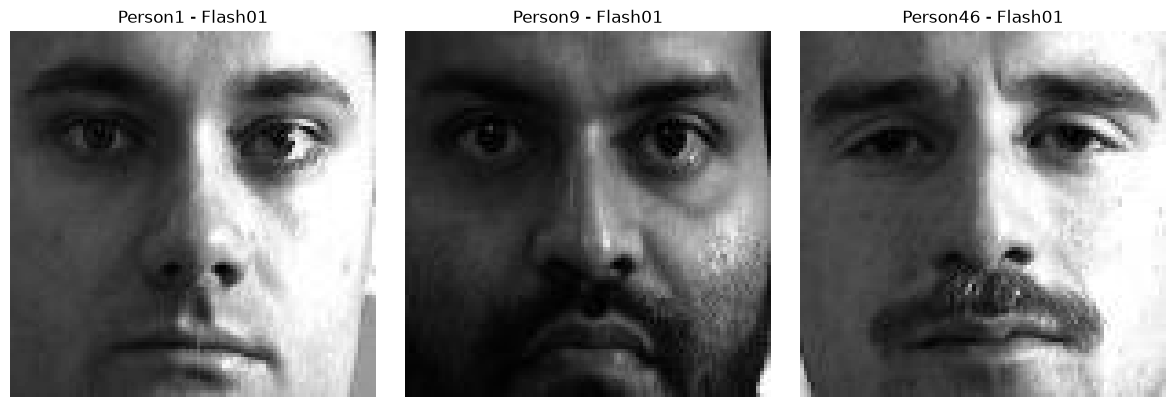

In [33]:
# Q3: SVD-based Image Denoising

selected_indices = [0, 42, 84]

image_names = [
    "Person1 - Flash01",
    "Person9 - Flash01",
    "Person46 - Flash01"
]

clean_images = [
    X_lights[i].reshape(100, 100).astype(np.float64)
    for i in selected_indices
]

# Display original images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, name in zip(axes, clean_images, image_names):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_original_images.png", dpi=200)
plt.show()

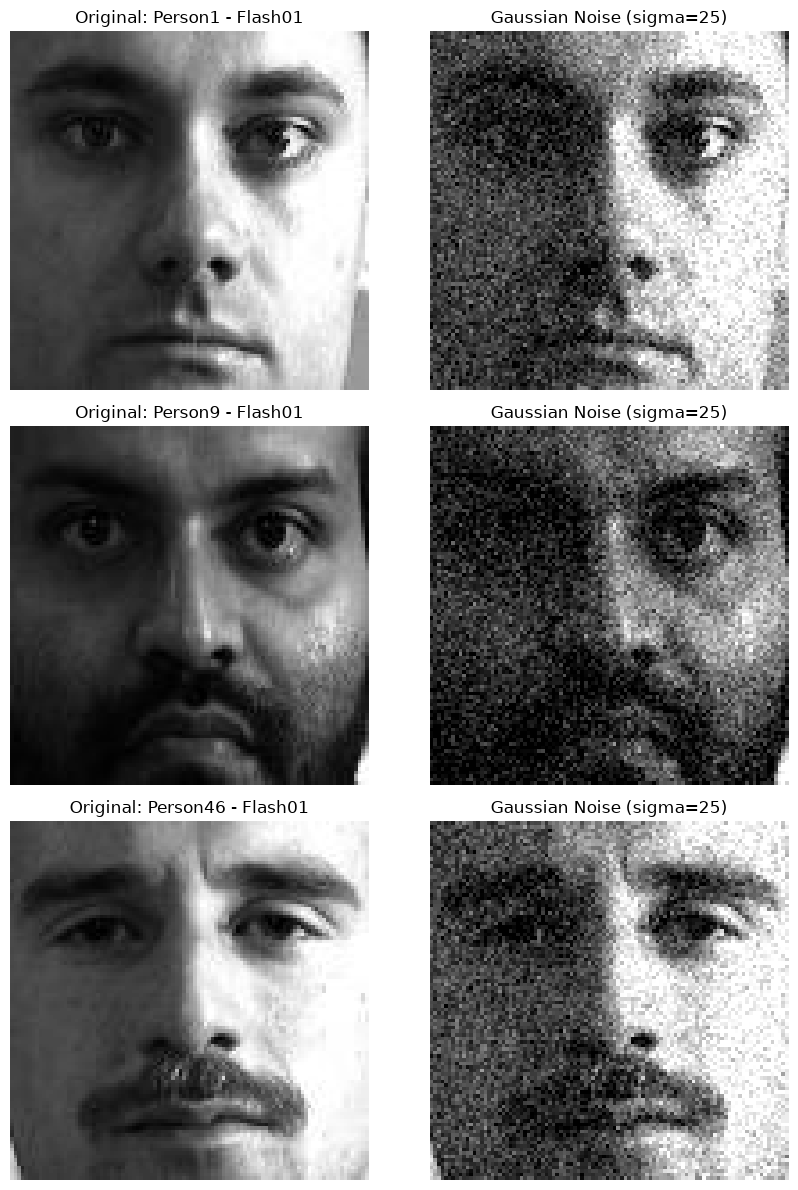

In [34]:
def add_gaussian_noise(image, sigma=25):
    noise = np.random.normal(
        loc=0,
        scale=sigma,
        size=image.shape
    )

    noisy_image = image + noise

    return np.clip(noisy_image, 0, 255)


gaussian_noisy_images = [
    add_gaussian_noise(img, sigma=25)
    for img in clean_images
]

fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for i in range(3):
    axes[i, 0].imshow(
        clean_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title(f"Original: {image_names[i]}")

    axes[i, 1].imshow(
        gaussian_noisy_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title("Gaussian Noise (sigma=25)")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_gaussian_noise.png", dpi=200)
plt.show()

In [35]:
def manual_svd(A):
    # Step 1: Calculate A transpose multiplied by A
    ATA = A.T @ A

    # Step 2: Eigen decomposition
    eigenvalues, V = np.linalg.eigh(ATA)

    # Step 3: Sort eigenvalues in descending order
    indices = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[indices]
    V = V[:, indices]

    # Step 4: Calculate singular values
    eigenvalues = np.maximum(eigenvalues, 0)
    singular_values = np.sqrt(eigenvalues)

    # Step 5: Calculate left singular vectors
    tolerance = 1e-10
    valid = singular_values > tolerance

    singular_values = singular_values[valid]
    V = V[:, valid]

    U = (A @ V) / singular_values

    return U, singular_values, V.T

In [36]:
def reconstruct_svd(U, S, VT, k):
    U_k = U[:, :k]
    S_k = np.diag(S[:k])
    VT_k = VT[:k, :]

    reconstructed = U_k @ S_k @ VT_k

    return np.clip(reconstructed, 0, 255)

In [37]:
svd_results = []

for noisy_image in gaussian_noisy_images:

    U, S, VT = manual_svd(noisy_image)

    reconstructions = {}

    for k in [5, 20, 50]:
        reconstructions[k] = reconstruct_svd(U, S, VT, k)

    svd_results.append({
        "U": U,
        "S": S,
        "VT": VT,
        "reconstructions": reconstructions
    })

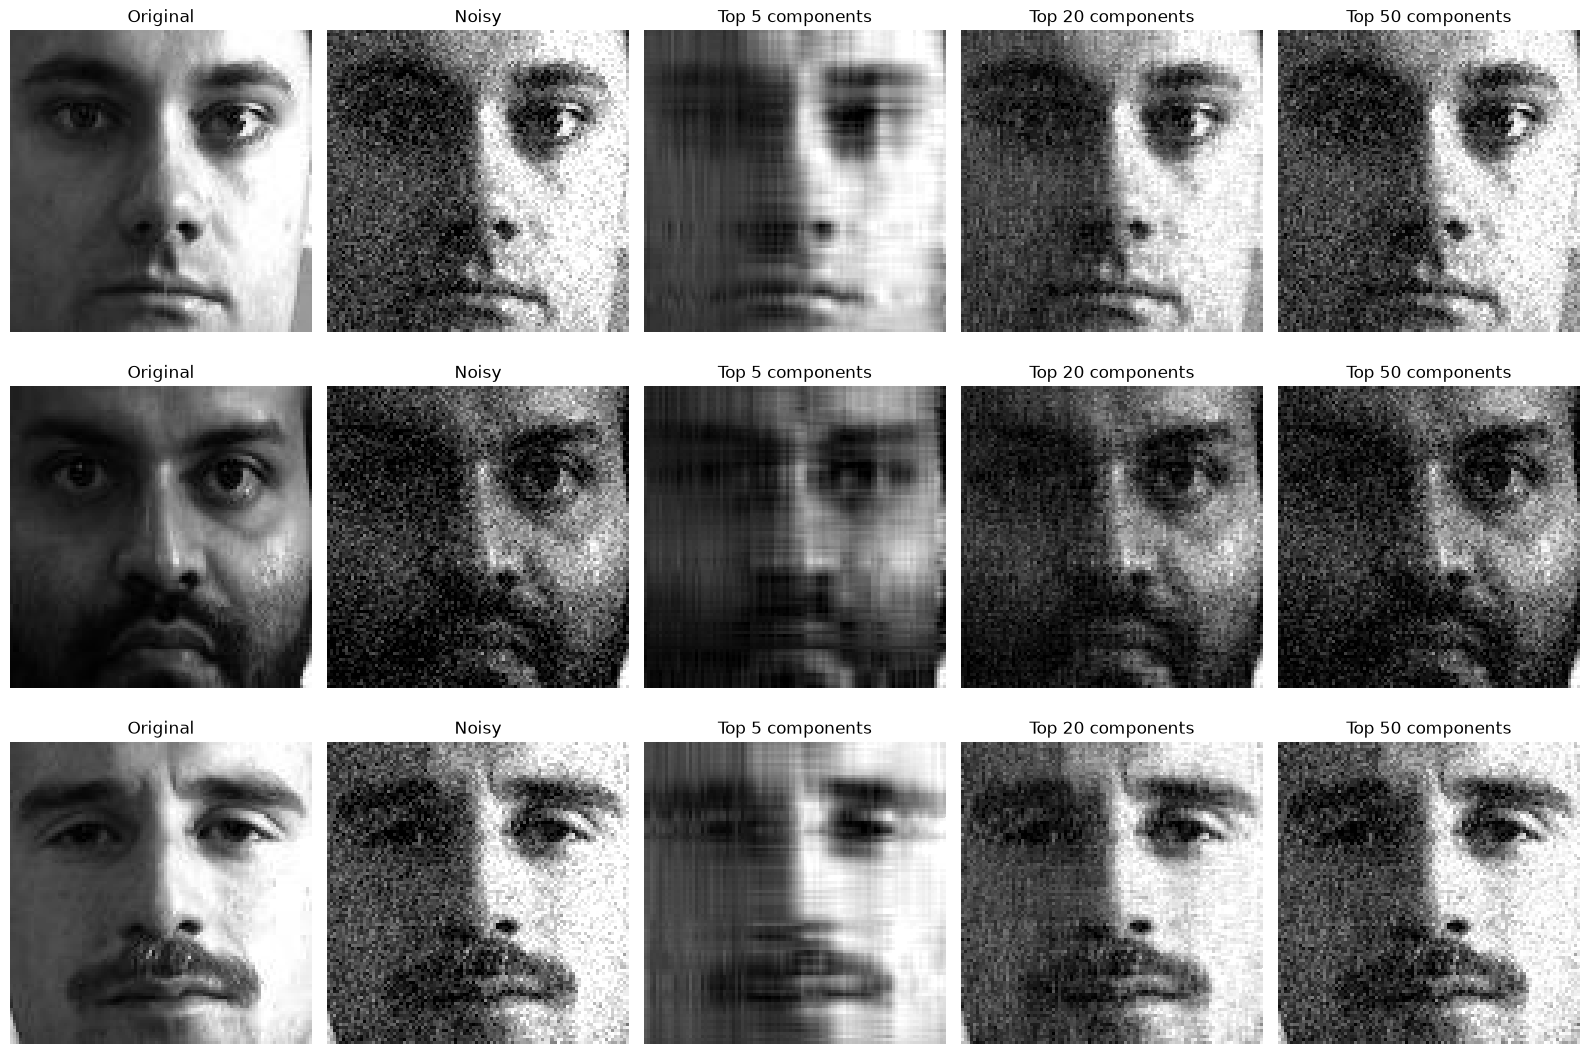

In [38]:
fig, axes = plt.subplots(3, 5, figsize=(16, 11))

for i in range(3):
    axes[i, 0].imshow(
        clean_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(
        gaussian_noisy_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title("Noisy")

    for j, k in enumerate([5, 20, 50]):
        axes[i, j + 2].imshow(
            svd_results[i]["reconstructions"][k],
            cmap="gray", vmin=0, vmax=255
        )
        axes[i, j + 2].set_title(f"Top {k} components")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_svd_reconstruction.png", dpi=200)
plt.show()

In [39]:
mse_results = []

for i in range(3):
    for k in [5, 20, 50]:

        reconstructed = svd_results[i]["reconstructions"][k]

        mse = np.mean(
            (clean_images[i] - reconstructed) ** 2
        )

        mse_results.append({
            "Image": image_names[i],
            "Components": k,
            "MSE": mse
        })

mse_df = pd.DataFrame(mse_results)

display(mse_df)

,Image,Components,MSE
0,Person1 - Flash01,5,267.462588
1,Person1 - Flash01,20,296.875691
2,Person1 - Flash01,50,484.140417
3,Person9 - Flash01,5,194.830277
4,Person9 - Flash01,20,297.956847
5,Person9 - Flash01,50,477.056514
6,Person46 - Flash01,5,280.836729
7,Person46 - Flash01,20,301.455248
8,Person46 - Flash01,50,474.815348


In [40]:
clean_svd_results = []

for image in clean_images:
    U, S, VT = manual_svd(image)

    clean_svd_results.append(S)

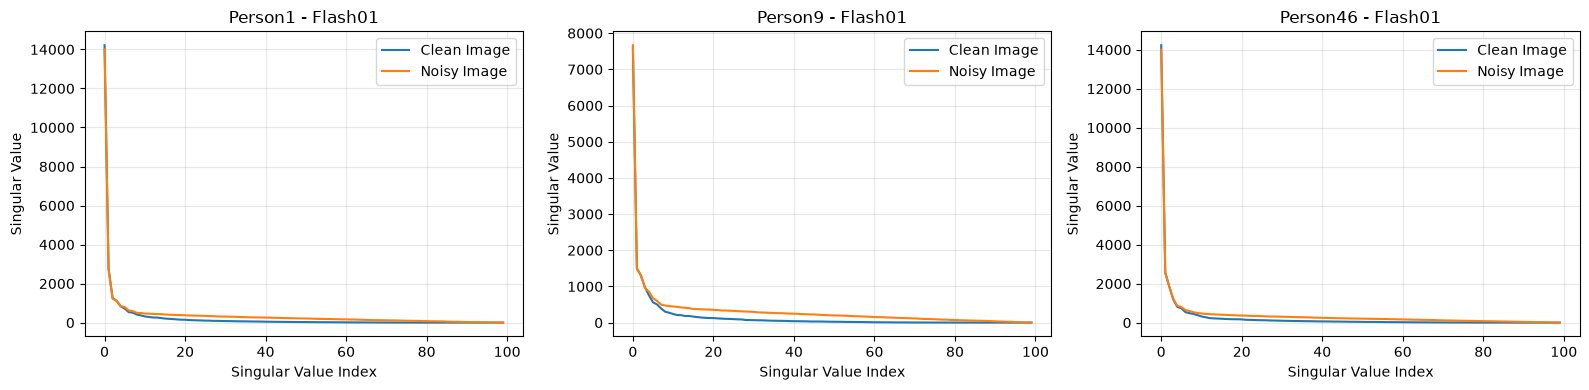

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i in range(3):

    clean_S = clean_svd_results[i]
    noisy_S = svd_results[i]["S"]

    axes[i].plot(
        clean_S, label="Clean Image"
    )

    axes[i].plot(
        noisy_S, label="Noisy Image"
    )

    axes[i].set_title(image_names[i])
    axes[i].set_xlabel("Singular Value Index")
    axes[i].set_ylabel("Singular Value")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_singular_values.png", dpi=200)
plt.show()

In [42]:
def add_salt_pepper_noise(image, amount=0.05):

    noisy = image.copy()

    total_pixels = image.size
    n_salt = int(total_pixels * amount / 2)
    n_pepper = int(total_pixels * amount / 2)

    salt_coords = (
        np.random.randint(0, image.shape[0], n_salt),
        np.random.randint(0, image.shape[1], n_salt)
    )

    pepper_coords = (
        np.random.randint(0, image.shape[0], n_pepper),
        np.random.randint(0, image.shape[1], n_pepper)
    )

    noisy[salt_coords] = 255
    noisy[pepper_coords] = 0

    return noisy


sp_noisy_images = [
    add_salt_pepper_noise(img, amount=0.05)
    for img in clean_images
]

In [43]:
sp_svd_results = []

for noisy_image in sp_noisy_images:

    U, S, VT = manual_svd(noisy_image)

    reconstructions = {}

    for k in [5, 20, 50]:
        reconstructions[k] = reconstruct_svd(U, S, VT, k)

    sp_svd_results.append({
        "U": U,
        "S": S,
        "VT": VT,
        "reconstructions": reconstructions
    })

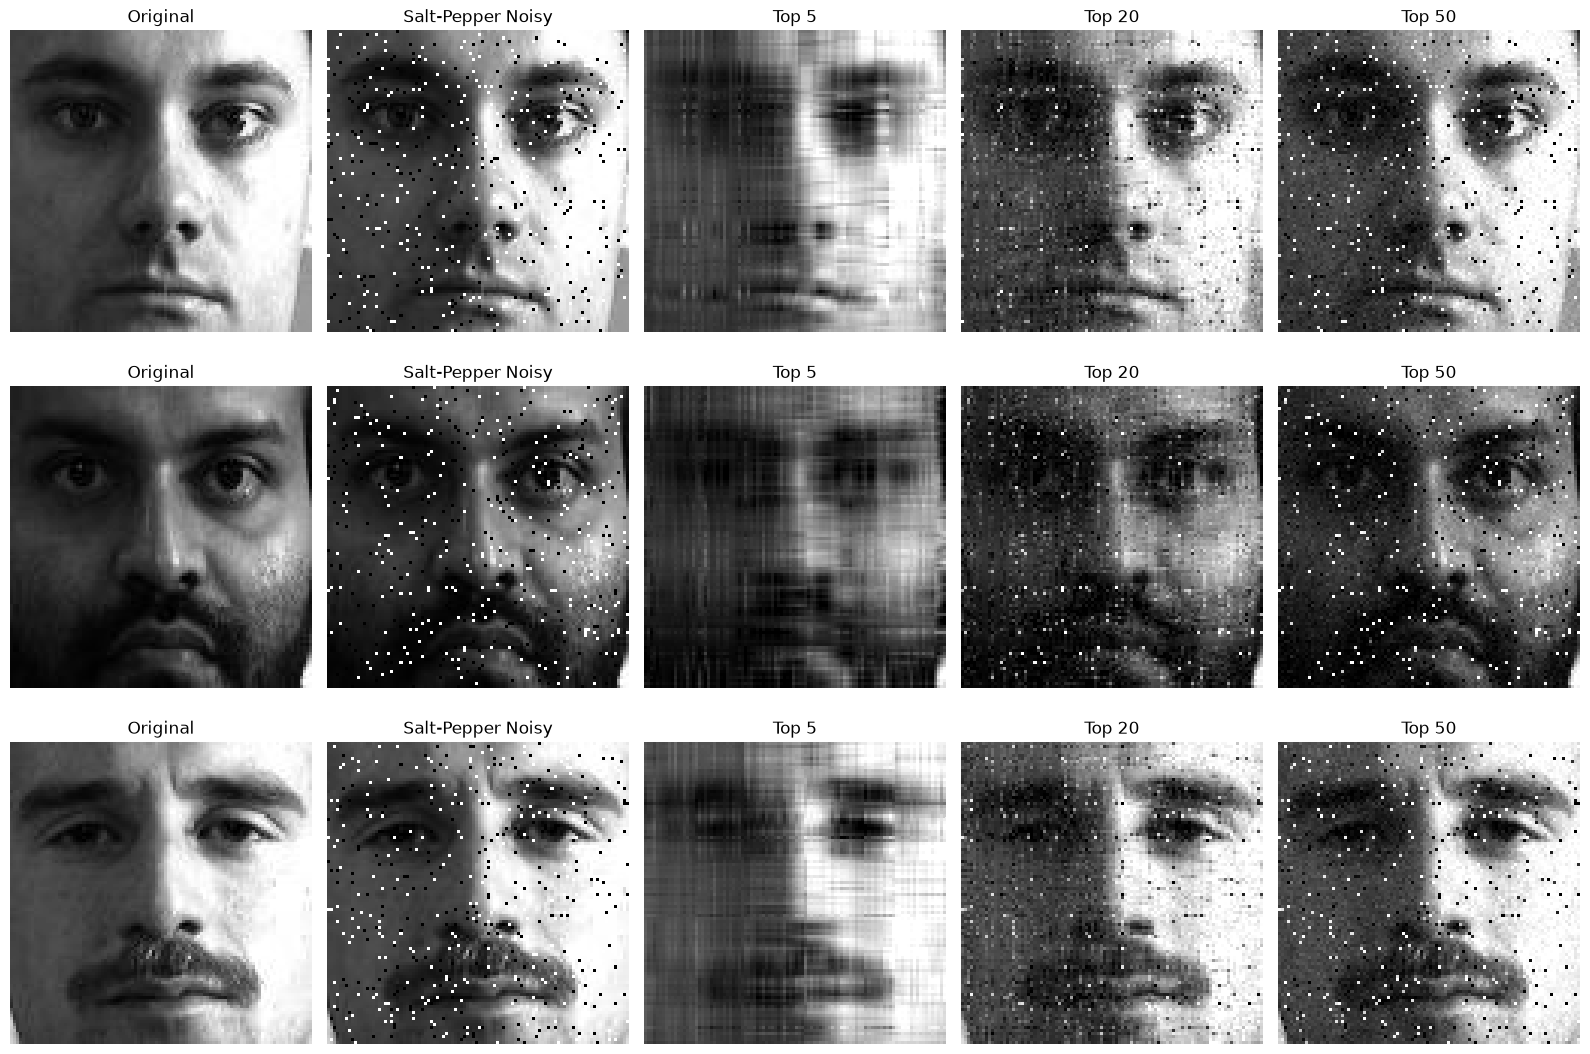

In [44]:
fig, axes = plt.subplots(3, 5, figsize=(16, 11))

for i in range(3):

    axes[i, 0].imshow(
        clean_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(
        sp_noisy_images[i], cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title("Salt-Pepper Noisy")

    for j, k in enumerate([5, 20, 50]):
        axes[i, j + 2].imshow(
            sp_svd_results[i]["reconstructions"][k],
            cmap="gray", vmin=0, vmax=255
        )
        axes[i, j + 2].set_title(f"Top {k}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_salt_pepper_reconstruction.png", dpi=200)
plt.show()

In [45]:
sp_mse_results = []

for i in range(3):

    # MSE of noisy image before reconstruction
    noisy_mse = np.mean(
        (clean_images[i] - sp_noisy_images[i]) ** 2
    )

    sp_mse_results.append({
        "Image": image_names[i],
        "Components": "Noisy",
        "MSE": noisy_mse
    })

    for k in [5, 20, 50]:

        reconstructed = sp_svd_results[i]["reconstructions"][k]

        mse = np.mean(
            (clean_images[i] - reconstructed) ** 2
        )

        sp_mse_results.append({
            "Image": image_names[i],
            "Components": k,
            "MSE": mse
        })

sp_mse_df = pd.DataFrame(sp_mse_results)

display(sp_mse_df)

,Image,Components,MSE
0,Person1 - Flash01,Noisy,1096.796500
1,Person1 - Flash01,5,349.233586
2,Person1 - Flash01,20,652.830516
3,Person1 - Flash01,50,993.989149
4,Person9 - Flash01,Noisy,1088.978200
5,Person9 - Flash01,5,264.721991
6,Person9 - Flash01,20,639.870978
7,Person9 - Flash01,50,984.374480
8,Person46 - Flash01,Noisy,1132.116800
9,Person46 - Flash01,5,358.034988


In [46]:
noise_comparison = []

for i in range(3):

    # Gaussian noise baseline
    gaussian_baseline = np.mean(
        (clean_images[i] - gaussian_noisy_images[i]) ** 2
    )

    noise_comparison.append({
        "Image": image_names[i],
        "Noise Type": "Gaussian",
        "Components": "Noisy",
        "MSE": gaussian_baseline
    })

    for k in [5, 20, 50]:
        mse = np.mean(
            (clean_images[i] -
             svd_results[i]["reconstructions"][k]) ** 2
        )

        noise_comparison.append({
            "Image": image_names[i],
            "Noise Type": "Gaussian",
            "Components": k,
            "MSE": mse
        })

    # Salt-and-Pepper noise baseline
    sp_baseline = np.mean(
        (clean_images[i] - sp_noisy_images[i]) ** 2
    )

    noise_comparison.append({
        "Image": image_names[i],
        "Noise Type": "Salt-and-Pepper",
        "Components": "Noisy",
        "MSE": sp_baseline
    })

    for k in [5, 20, 50]:
        mse = np.mean(
            (clean_images[i] -
             sp_svd_results[i]["reconstructions"][k]) ** 2
        )

        noise_comparison.append({
            "Image": image_names[i],
            "Noise Type": "Salt-and-Pepper",
            "Components": k,
            "MSE": mse
        })

noise_comparison_df = pd.DataFrame(noise_comparison)

display(noise_comparison_df)

,Image,Noise Type,Components,MSE
0,Person1 - Flash01,Gaussian,Noisy,549.836997
1,Person1 - Flash01,Gaussian,5,267.462588
2,Person1 - Flash01,Gaussian,20,296.875691
3,Person1 - Flash01,Gaussian,50,484.140417
4,Person1 - Flash01,Salt-and-Pepper,Noisy,1096.796500
5,Person1 - Flash01,Salt-and-Pepper,5,349.233586
6,Person1 - Flash01,Salt-and-Pepper,20,652.830516
7,Person1 - Flash01,Salt-and-Pepper,50,993.989149
8,Person9 - Flash01,Gaussian,Noisy,540.224349
9,Person9 - Flash01,Gaussian,5,194.830277


In [47]:
noise_levels = [10, 25, 50]
noise_level_results = []

for i, image in enumerate(clean_images):

    for sigma in noise_levels:

        noisy = add_gaussian_noise(image, sigma=sigma)

        U, S, VT = manual_svd(noisy)

        baseline_mse = np.mean((image - noisy) ** 2)

        for k in [5, 20, 50]:

            reconstructed = reconstruct_svd(U, S, VT, k)

            mse = np.mean((image - reconstructed) ** 2)

            noise_level_results.append({
                "Image": image_names[i],
                "Sigma": sigma,
                "Components": k,
                "Noisy MSE": baseline_mse,
                "Reconstructed MSE": mse
            })

noise_level_df = pd.DataFrame(noise_level_results)

display(noise_level_df)

,Image,Sigma,Components,Noisy MSE,Reconstructed MSE
0,Person1 - Flash01,10,5,92.201859,217.882285
1,Person1 - Flash01,10,20,92.201859,55.969993
2,Person1 - Flash01,10,50,92.201859,81.198831
3,Person1 - Flash01,25,5,548.894283,281.342816
4,Person1 - Flash01,25,20,548.894283,299.780659
5,Person1 - Flash01,25,50,548.894283,487.315739
6,Person1 - Flash01,50,5,1928.851577,517.463404
7,Person1 - Flash01,50,20,1928.851577,1080.424309
8,Person1 - Flash01,50,50,1928.851577,1688.806124
9,Person9 - Flash01,10,5,94.234424,143.496051


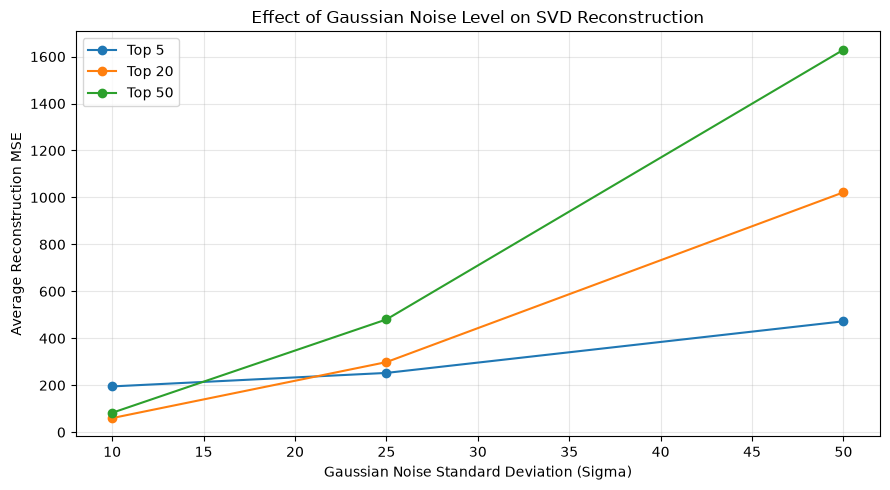

In [48]:
avg_noise_results = (
    noise_level_df
    .groupby(["Sigma", "Components"])["Reconstructed MSE"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

for k in [5, 20, 50]:

    subset = avg_noise_results[
        avg_noise_results["Components"] == k
    ]

    ax.plot(
        subset["Sigma"],
        subset["Reconstructed MSE"],
        marker="o",
        label=f"Top {k}"
    )

ax.set_xlabel("Gaussian Noise Standard Deviation (Sigma)")
ax.set_ylabel("Average Reconstruction MSE")
ax.set_title("Effect of Gaussian Noise Level on SVD Reconstruction")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_noise_level_analysis.png", dpi=200)
plt.show()

In [49]:
np.random.seed(42)

## Q4. SVD-based Movie Recommendation System

In [51]:
print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)
print("MovieLens directory:", PROJECT_ROOT / "data" / "raw" / "ml-100k")

Project root: /home/aryan/projects/dsl502-assignment
Raw data directory: /home/aryan/projects/dsl502-assignment/data/raw/PCA_PIE_Data
MovieLens directory: /home/aryan/projects/dsl502-assignment/data/raw/ml-100k


In [52]:
MOVIELENS_DIR = PROJECT_ROOT / "data" / "raw" / "ml-100k"

ratings_path = MOVIELENS_DIR / "u.data"
movies_path = MOVIELENS_DIR / "u.item"

print("Ratings file exists:", ratings_path.exists())
print("Movies file exists:", movies_path.exists())

Ratings file exists: True
Movies file exists: True


In [53]:
with open(ratings_path, "r", encoding="latin-1") as f:
    for _ in range(5):
        print(f.readline().strip())

196	242	3	881250949
186	302	3	891717742
22	377	1	878887116
244	51	2	880606923
166	346	1	886397596


In [54]:
ratings = pd.read_csv(
    ratings_path,
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"]
)

movies = pd.read_csv(
    movies_path,
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["movie_id", "title"]
)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

display(ratings.head())
display(movies.head())

Ratings shape: (100000, 4)
Movies shape: (1682, 2)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [55]:
print("Total ratings:", len(ratings))
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies:", ratings["movie_id"].nunique())

print("\nRating distribution:")
display(ratings["rating"].value_counts().sort_index())

print("\nMissing values:")
print(ratings.isnull().sum())

Total ratings: 100000
Unique users: 943
Unique movies: 1682

Rating distribution:


rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


In [57]:
# Reproducible 80/20 split
np.random.seed(42)

n_ratings = len(ratings)

indices = np.random.permutation(n_ratings)

split_point = int(0.80 * n_ratings)

train_indices = indices[:split_point]
test_indices = indices[split_point:]

train_ratings = ratings.iloc[train_indices].copy()
test_ratings = ratings.iloc[test_indices].copy()

print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))

Training ratings: 80000
Testing ratings: 20000


In [58]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()

R_train = np.zeros((n_users, n_movies), dtype=np.float64)

for row in train_ratings.itertuples(index=False):
    user_idx = row.user_id - 1
    movie_idx = row.movie_id - 1

    R_train[user_idx, movie_idx] = row.rating

print("Training matrix shape:", R_train.shape)
print("Non-zero ratings:", np.count_nonzero(R_train))
print("Matrix density:", 
      np.count_nonzero(R_train) / R_train.size * 100, "%")

Training matrix shape: (943, 1682)
Non-zero ratings: 80000
Matrix density: 5.043735491379626 %


In [59]:
print("First 5 users and first 10 movies:")
display(pd.DataFrame(R_train[:5, :10]))

print("Training matrix minimum:", R_train.min())
print("Training matrix maximum:", R_train.max())

First 5 users and first 10 movies:


,0,1,2,3,4,5,6,7,8,9
0,5.0,0.0,4.0,3.0,0.0,5.0,4.0,1.0,0.0,3.0
1,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Training matrix minimum: 0.0
Training matrix maximum: 5.0


In [60]:
# Calculate each user's mean rating from training data
user_means = np.zeros(n_users)

for user_idx in range(n_users):

    rated_movies = R_train[user_idx] > 0

    if np.any(rated_movies):
        user_means[user_idx] = np.mean(
            R_train[user_idx, rated_movies]
        )

# Create centered matrix
R_centered = np.zeros_like(R_train)

for user_idx in range(n_users):

    rated_movies = R_train[user_idx] > 0

    R_centered[user_idx, rated_movies] = (
        R_train[user_idx, rated_movies]
        - user_means[user_idx]
    )

print("Centered matrix shape:", R_centered.shape)
print("Centered matrix minimum:", R_centered.min())
print("Centered matrix maximum:", R_centered.max())
print("Non-zero entries:", np.count_nonzero(R_centered))

Centered matrix shape: (943, 1682)
Centered matrix minimum: -3.719298245614035
Centered matrix maximum: 3.5492537313432835
Non-zero entries: 79738


In [61]:
def manual_svd_recommender(A):

    # Step 1: Calculate smaller Gram matrix
    G = A @ A.T

    # Step 2: Eigen decomposition
    eigenvalues, U = np.linalg.eigh(G)

    # Step 3: Sort in descending order
    indices = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[indices]
    U = U[:, indices]

    # Step 4: Calculate singular values
    eigenvalues = np.maximum(eigenvalues, 0)
    singular_values = np.sqrt(eigenvalues)

    # Step 5: Remove numerical zero singular values
    tolerance = 1e-10
    valid = singular_values > tolerance

    singular_values = singular_values[valid]
    U = U[:, valid]

    # Step 6: Calculate right singular vectors
    Vt = (U.T @ A) / singular_values[:, None]

    return U, singular_values, Vt

In [62]:
U_rec, S_rec, VT_rec = manual_svd_recommender(R_centered)

print("U shape:", U_rec.shape)
print("Singular values shape:", S_rec.shape)
print("VT shape:", VT_rec.shape)
print("Number of singular values:", len(S_rec))

U shape: (943, 943)
Singular values shape: (943,)
VT shape: (943, 1682)
Number of singular values: 943


In [63]:
# Calculate singular value energy
singular_value_energy = S_rec ** 2

total_energy = np.sum(singular_value_energy)

explained_energy = singular_value_energy / total_energy

cumulative_energy = np.cumsum(explained_energy) * 100

# Energy captured by selected k values
for k in [5, 10, 20, 50, 100]:
    print(f"Top {k} components: {cumulative_energy[k-1]:.2f}%")

# Find components needed for 90% energy
k_90 = np.searchsorted(cumulative_energy, 90) + 1

print("\nComponents required for 90% energy:", k_90)

Top 5 components: 10.95%
Top 10 components: 15.52%
Top 20 components: 22.53%
Top 50 components: 38.27%
Top 100 components: 56.30%

Components required for 90% energy: 321


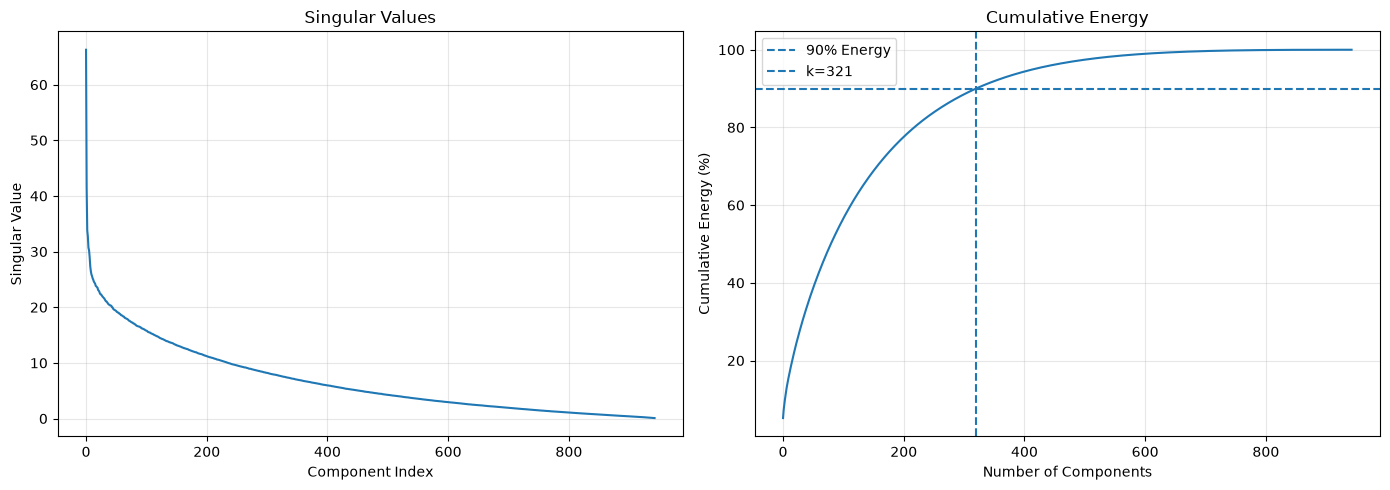

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(S_rec)
axes[0].set_title("Singular Values")
axes[0].set_xlabel("Component Index")
axes[0].set_ylabel("Singular Value")
axes[0].grid(alpha=0.3)

axes[1].plot(cumulative_energy)
axes[1].axhline(90, linestyle="--", label="90% Energy")
axes[1].axvline(k_90 - 1, linestyle="--", label=f"k={k_90}")
axes[1].set_title("Cumulative Energy")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Energy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q4_singular_value_energy.png", dpi=200)
plt.show()

In [65]:
K_VALUES = [5, 10, 20, 50, 100]

predicted_matrices = {}

for k in K_VALUES:

    U_k = U_rec[:, :k]
    S_k = S_rec[:k]
    VT_k = VT_rec[:k, :]

    # Reconstruct centered rating matrix
    R_pred_centered = (
        U_k * S_k
    ) @ VT_k

    # Add each user's training mean
    R_pred = R_pred_centered + user_means[:, np.newaxis]

    # Rating scale is 1 to 5
    R_pred = np.clip(R_pred, 1, 5)

    predicted_matrices[k] = R_pred

    print(f"k={k}: Prediction matrix shape = {R_pred.shape}")

k=5: Prediction matrix shape = (943, 1682)
k=10: Prediction matrix shape = (943, 1682)
k=20: Prediction matrix shape = (943, 1682)
k=50: Prediction matrix shape = (943, 1682)
k=100: Prediction matrix shape = (943, 1682)


In [66]:
evaluation_results = []

for k in K_VALUES:

    actual_ratings = []
    predicted_ratings = []

    for row in test_ratings.itertuples(index=False):

        user_idx = row.user_id - 1
        movie_idx = row.movie_id - 1

        actual_ratings.append(row.rating)

        predicted_ratings.append(
            predicted_matrices[k][user_idx, movie_idx]
        )

    actual_ratings = np.array(actual_ratings)
    predicted_ratings = np.array(predicted_ratings)

    mae = np.mean(np.abs(actual_ratings - predicted_ratings))

    rmse = np.sqrt(
        np.mean((actual_ratings - predicted_ratings) ** 2)
    )

    evaluation_results.append({
        "Components (k)": k,
        "MAE": mae,
        "RMSE": rmse
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

,Components (k),MAE,RMSE
0,5,0.784795,0.991852
1,10,0.780559,0.987493
2,20,0.783247,0.991055
3,50,0.795900,1.005334
4,100,0.811093,1.021614


In [70]:
BEST_K = 10

best_predictions = predicted_matrices[BEST_K]

selected_users = [1, 10, 100, 500, 943]

recommendations = []

for user_id in selected_users:

    user_idx = user_id - 1

    # Exclude movies already rated by this user
    rated_movie_ids = set(
        train_ratings.loc[
            train_ratings["user_id"] == user_id,
            "movie_id"
        ]
    )

    # Predicted ratings for all movies
    user_predictions = best_predictions[user_idx]

    # Sort movies by predicted rating
    ranked_indices = np.argsort(user_predictions)[::-1]

    count = 0

    for movie_idx in ranked_indices:

        movie_id = movie_idx + 1

        if movie_id not in rated_movie_ids:

            recommendations.append({
                "User ID": user_id,
                "Movie ID": movie_id,
                "Movie Title": movies.loc[
                    movies["movie_id"] == movie_id, "title"
                ].iloc[0],
                "Predicted Rating": user_predictions[movie_idx]
            })

            count += 1

            if count == 10:
                break

recommendations_df = pd.DataFrame(recommendations)

display(recommendations_df)

,User ID,Movie ID,Movie Title,Predicted Rating
0,1,408,"Close Shave, A (1995)",4.321672
1,1,313,Titanic (1997),4.282803
2,1,302,L.A. Confidential (1997),4.168948
3,1,210,Indiana Jones and the Last Crusade (1989),4.154509
4,1,474,Dr. Strangelove or: How I Learned to Stop Worr...,4.126555
5,1,183,Alien (1979),4.115789
6,1,475,Trainspotting (1996),4.107575
7,1,483,Casablanca (1942),4.098513
8,1,98,"Silence of the Lambs, The (1991)",4.098452
9,1,268,Chasing Amy (1997),4.090972


In [71]:
prediction_examples = []

for row in test_ratings.head(10).itertuples(index=False):

    user_idx = row.user_id - 1
    movie_idx = row.movie_id - 1

    prediction_examples.append({
        "User ID": row.user_id,
        "Movie ID": row.movie_id,
        "Actual Rating": row.rating,
        "Predicted Rating": best_predictions[user_idx, movie_idx]
    })

prediction_examples_df = pd.DataFrame(prediction_examples)

display(prediction_examples_df)

,User ID,Movie ID,Actual Rating,Predicted Rating
0,907,143,5,4.556974
1,371,210,4,4.164169
2,218,42,4,3.503417
3,829,170,4,3.543349
4,733,277,1,3.012074
5,363,1512,1,3.127499
6,193,487,5,3.184551
7,808,313,5,4.150590
8,557,682,2,3.723427
9,774,196,3,2.001942


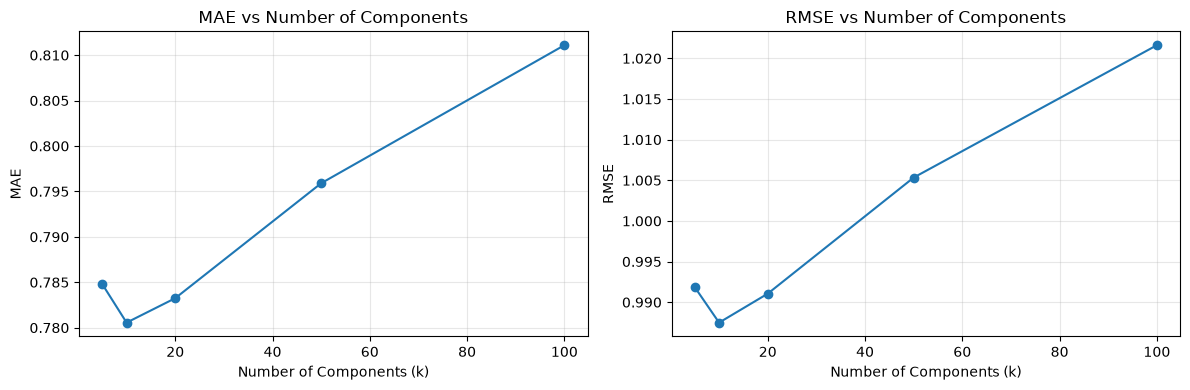

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    evaluation_df["Components (k)"],
    evaluation_df["MAE"],
    marker="o"
)
axes[0].set_title("MAE vs Number of Components")
axes[0].set_xlabel("Number of Components (k)")
axes[0].set_ylabel("MAE")
axes[0].grid(alpha=0.3)

axes[1].plot(
    evaluation_df["Components (k)"],
    evaluation_df["RMSE"],
    marker="o"
)
axes[1].set_title("RMSE vs Number of Components")
axes[1].set_xlabel("Number of Components (k)")
axes[1].set_ylabel("RMSE")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q4_model_evaluation.png", dpi=200)
plt.show()